In [ ]:
import stpsf
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import QTable
from astropy.visualization import simple_norm
from photutils.aperture import CircularAperture
from photutils.datasets import make_noise_image
from photutils.detection import DAOStarFinder
from photutils.psf import (ImagePSF, CircularGaussianPRF, PSFPhotometry,
                           make_psf_model_image)



**WARNING**: LOCAL JWST PRD VERSION PRDOPSSOC-073 DOESN'T MATCH THE CURRENT ONLINE VERSION PRDOPSSOC-075
Please consider updating pysiaf, e.g. pip install --upgrade pysiaf or conda update pysiaf


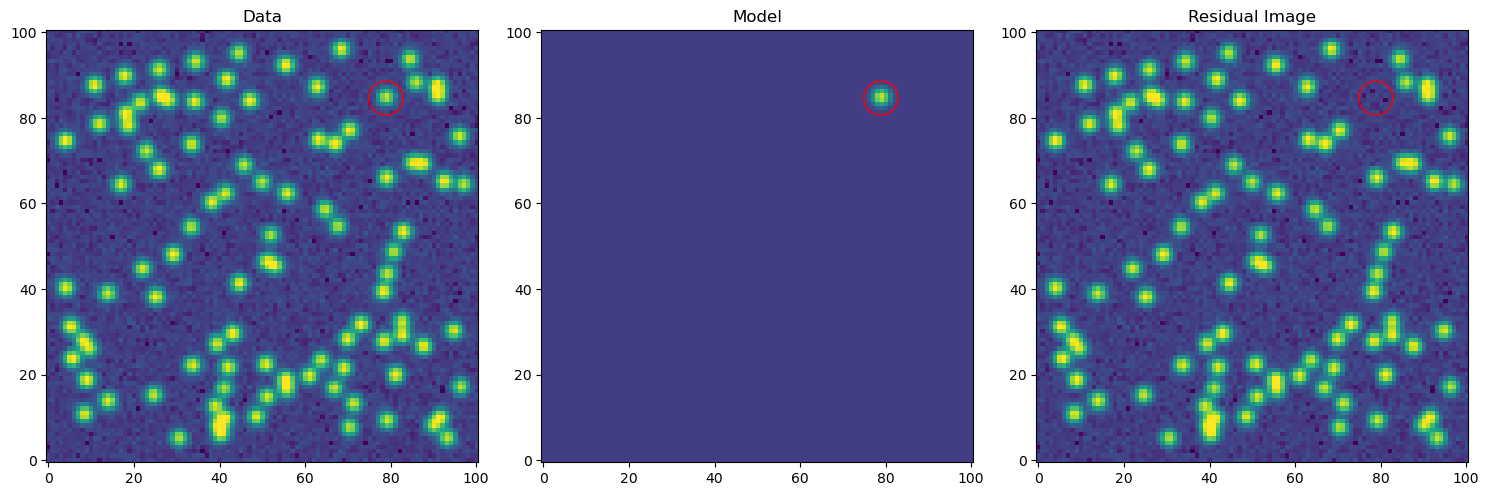

In [ ]:
psf_model = CircularGaussianPRF(flux=1, fwhm=2.7)
psf_shape = (9, 9)
n_sources = 100

shape = (101, 101)
data, true_params = make_psf_model_image(shape, psf_model, n_sources,
                                         model_shape=psf_shape,
                                         flux=(500, 700),
                                         min_separation=2, seed=5)

#print(true_params)

noise = make_noise_image(data.shape, mean=0, stddev=1, seed=0)
data += noise
error = np.full(data.shape, 1.0)



psf_model = CircularGaussianPRF(flux=1, fwhm=2.7)
fit_shape = (5, 5)
finder = DAOStarFinder(6.0, 2.0)
psfphot = PSFPhotometry(psf_model, fit_shape, finder=finder,
                        aperture_radius=4)

init_params         = QTable()
init_params['x']    = [78.86527190832035]
init_params['y']    = [ 84.65433337111199]
phot                = psfphot(data, error=error, init_params=init_params)

resid = psfphot.make_residual_image(data)
xypos = zip(phot['x_fit'], phot['y_fit'], strict=True)
aper = CircularAperture(xypos, r=4)

fig, ax = plt.subplots(ncols=3, figsize=(15, 5))
norm = simple_norm(data, 'sqrt', percent=99)
ax[0].imshow(data, norm=norm, origin='lower')
ax[1].imshow(data - resid, norm=norm, origin='lower')
im = ax[2].imshow(resid, norm=norm, origin='lower')
ax[0].set_title('Data')
aper.plot(ax=ax[0], color='red')
ax[1].set_title('Model')
aper.plot(ax=ax[1], color='red')
ax[2].set_title('Residual Image')
aper.plot(ax=ax[2], color='red')
fig.tight_layout()

In [ ]:
nrc = stpsf.NIRCam()
nrc.filter = 'F200W'
nrc.detector = 'NRCA1'
nrc.detector_position = (1024, 1024)      # (x, y) on the detector


In [4]:
oversample      = 4
hdul            = nrc.calc_psf(oversample=oversample, fov_arcsec=2.4)
psf_oversampled = hdul['OVERSAMP'].data  

# normalize to 1
psf_oversampled = psf_oversampled / psf_oversampled.sum() * oversample**2

psf_model = ImagePSF(psf_oversampled, flux=1, x_0=0, y_0=0,
                     oversampling=oversample)

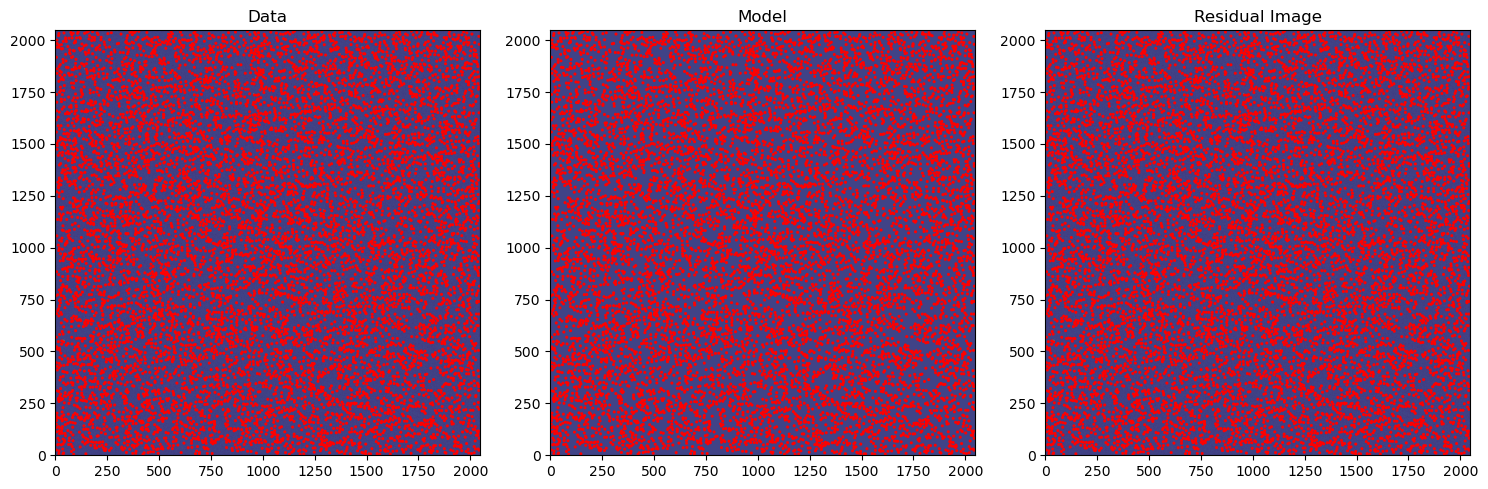

In [29]:
psf_shape = (9, 9)     
n_sources = 10000
shape = (2048, 2048)

data, true_params = make_psf_model_image(
    shape, psf_model, n_sources,
    model_shape=psf_shape,
    flux=(500, 700),
    min_separation=5,     
    seed=5)

noise = make_noise_image(data.shape, mean=0, stddev=1, seed=0)
data += noise
error = np.full(data.shape, 1.0)
init_params         = QTable()

init_params['x']    = [true_params['x_0'][0]]
init_params['y']    = [true_params['y_0'][0]]
phot                = psfphot(data, error=error,)# init_params=init_params)

resid = psfphot.make_residual_image(data)
xypos = zip(phot['x_fit'], phot['y_fit'], strict=True)
aper = CircularAperture(xypos, r=4)

fig, ax = plt.subplots(ncols=3, figsize=(15, 5))
norm = simple_norm(data, 'sqrt', percent=99)
ax[0].imshow(data, norm=norm, origin='lower')
ax[1].imshow(data - resid, norm=norm, origin='lower')
im = ax[2].imshow(resid, norm=norm, origin='lower')
ax[0].set_title('Data')
aper.plot(ax=ax[0], color='red')
ax[1].set_title('Model')
aper.plot(ax=ax[1], color='red')
ax[2].set_title('Residual Image')
aper.plot(ax=ax[2], color='red')
fig.tight_layout()

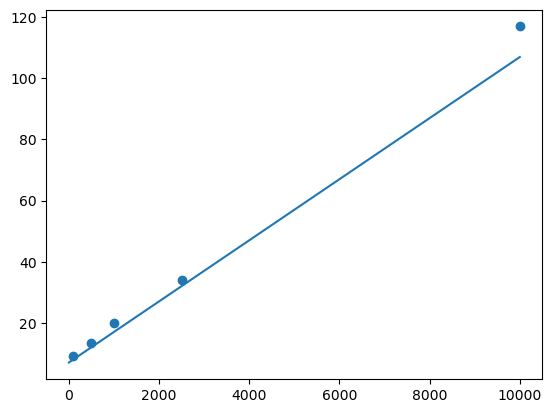

In [30]:
plt.scatter([100, 500, 1000, 2500, 10000], [9, 13.5,20, 34, 60+57])
plt.plot(np.linspace(0,10000), np.linspace(0,10000)*0.01 + 7)